# 01 — NOAA OISST Data Exploration

อ่านข้อมูล SST รายวันจาก NOAA OISST ปี 2021 บริเวณ -10° ถึง 35°N / 100° ถึง 160°E


In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import xarray as xr
from torch.utils.data import DataLoader, Dataset

try:
    from IPython.display import display
except ImportError:  # รันนอก Jupyter
    display = print

# --- Paths ---
PROJECT_DIR = Path("/home/kankrit/Projects/ocean-forecasting")
RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "reports"
MODEL_DIR = PROJECT_DIR / "models"
for d in (RAW_DIR, REPORT_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- พื้นที่ศึกษา ---
LAT_MIN, LAT_MAX = -10.0, 35.0
LON_MIN, LON_MAX = 100.0, 160.0

# --- ช่วงเวลา ---
YEARS = range(2017, 2022)
TEST_START = pd.Timestamp("2021-01-01")  # ปี 2021 = Test set

# --- โมเดล / การเทรน ---
INPUT_DAYS = 7          # ใช้ข้อมูลย้อนหลังกี่วัน
EVAL_HORIZONS = (1, 3, 7)
BATCH_SIZE = 4
EPOCHS = 15
PATIENCE = 3
LR = 1e-3
SEED = 42
DEVICE = torch.device("cpu")



In [47]:

# ## 2. โหลด SST (NOAA OISST)

def find_coord_name(ds, candidates):
    for name in candidates:
        if name in ds.coords or name in ds.dims or name in ds.variables:
            return name
    raise KeyError(f"Could not find any of these coordinates: {candidates}.")


def axis_slice(values, vmin, vmax):
    """slice ที่ถูกทิศ ไม่ว่าพิกัดจะเรียงจากน้อยไปมากหรือมากไปน้อย"""
    return slice(vmin, vmax) if values[0] < values[-1] else slice(vmax, vmin)


def load_oisst_year(year):
    """อ่านไฟล์ OISST ของปีนั้น แล้วตัดเฉพาะพื้นที่ศึกษา"""
    path = RAW_DIR / f"sst.day.mean.{year}.nc"
    if not path.exists():
        raise FileNotFoundError(f"❌ ไม่พบไฟล์ {path}")
    print(f"⏳ Reading local file for {year}...")
    with xr.open_dataset(path) as ds:
        lat_name = find_coord_name(ds, ("lat", "latitude"))
        lon_name = find_coord_name(ds, ("lon", "longitude"))
        time_name = find_coord_name(ds, ("time",))
        subset = ds["sst"].sel({
            time_name: slice(f"{year}-01-01", f"{year}-12-31"),
            lat_name: axis_slice(ds[lat_name].values, LAT_MIN, LAT_MAX),
            lon_name: axis_slice(ds[lon_name].values, LON_MIN, LON_MAX),
        }).load()
    return subset.to_dataset(name="sst")


def get_oisst_year(year):
    """ใช้ cache ถ้ามี ไม่งั้นอ่านจากไฟล์ต้นฉบับแล้วบันทึก cache"""
    cache = RAW_DIR / f"oisst_{year}_lat{LAT_MIN}_{LAT_MAX}_lon{LON_MIN}_{LON_MAX}.nc"
    if cache.exists():
        print(f"Using cache: {year}")
        with xr.open_dataset(cache) as ds:
            return ds.load()
    ds = load_oisst_year(year)
    ds.to_netcdf(cache)
    print(f"Saved cache: {year}")
    return ds


sst_years = [get_oisst_year(y) for y in YEARS]
time_name = find_coord_name(sst_years[0], ("time",))
ocean = xr.concat(sst_years, dim=time_name).sortby(time_name)
lat_name = find_coord_name(ocean, ("lat", "latitude"))
lon_name = find_coord_name(ocean, ("lon", "longitude"))
print("Combined shape:", ocean["sst"].shape)

# %%
# ### 2.1 เตรียม SST บนกริด 0.5° (ลดความละเอียดจาก 0.25° เป็นทุก 2 จุด)
dates_all = pd.DatetimeIndex(pd.to_datetime(ocean[time_name].values).normalize())

sst_model = (
    ocean["sst"]
    .transpose(time_name, lat_name, lon_name)
    .to_numpy()
    .astype(np.float32)[:, ::2, ::2]
)
target_lat = ocean[lat_name].values[::2]
target_lon = ocean[lon_name].values[::2]
T, H, W = sst_model.shape

split_idx = int(dates_all.searchsorted(TEST_START))
if split_idx >= T or dates_all[split_idx] != TEST_START:
    raise ValueError(f"{TEST_START.date()} is missing from the SST time index.")

# ocean_mask: เซลล์ที่เป็นทะเล (มีข้อมูล ≥ 95% ในช่วง Train เท่านั้น)
ocean_mask = np.isfinite(sst_model[:split_idx]).mean(axis=0) >= 0.95

print("✅ sst_model :", sst_model.shape)
print("✅ ocean_mask:", ocean_mask.shape, f"({ocean_mask.sum()} ocean cells)")
print("✅ split_idx :", split_idx, f"-> test starts {dates_all[split_idx].date()}")



Using cache: 2017
Using cache: 2018
Using cache: 2019
Using cache: 2020
Using cache: 2021
Combined shape: (1826, 180, 240)
✅ sst_model : (1826, 90, 120)
✅ ocean_mask: (90, 120) (8515 ocean cells)
✅ split_idx : 1461 -> test starts 2021-01-01


In [48]:

# ## 3. โหลดตัวแปรบรรยากาศ (รายเดือน → ปรับให้เป็นรายวันบนกริด SST)
#
# ข้อควรรู้: ข้อมูลรายเดือนมี timestamp ที่วันที่ 1 ของเดือน
# ถ้า interpolate ไปวันหลังจาก timestamp สุดท้ายจะได้ NaN
# จึงอ่านเผื่อไว้ 1 เดือนหน้า-หลัง และตัดพื้นที่แบบเผื่อขอบ 5° (กัน NaN ที่ขอบกริด)

PAD_START = dates_all[0] - pd.offsets.MonthBegin(1)
PAD_END = dates_all[-1] + pd.offsets.MonthBegin(1)
AREA_MARGIN = 5.0


def load_monthly_as_daily(filename, var):
    """อ่านตัวแปรรายเดือน -> interpolate เข้ากริด SST (0.5°) -> รายวัน, คืน (T, H, W)"""
    with xr.open_dataset(RAW_DIR / filename) as ds:
        da = ds[var]
        da = da.sel(
            time=slice(PAD_START, PAD_END),
            lat=axis_slice(da["lat"].values, LAT_MIN - AREA_MARGIN, LAT_MAX + AREA_MARGIN),
            lon=axis_slice(da["lon"].values, LON_MIN - AREA_MARGIN, LON_MAX + AREA_MARGIN),
        ).load()
    da = da.interp(lat=target_lat, lon=target_lon, method="linear")
    da = da.interp(time=dates_all, method="linear")
    return da.transpose("time", "lat", "lon").to_numpy().astype(np.float32)


atm_raw = {
    "u": load_monthly_as_daily("uwnd.mon.mean.nc", "uwnd"),
    "v": load_monthly_as_daily("vwnd.mon.mean.nc", "vwnd"),
    "slp": load_monthly_as_daily("slp.mon.mean.nc", "slp"),
    "precip": load_monthly_as_daily("precip.mon.mean.nc", "precip"),
}
for name, arr in atm_raw.items():
    assert arr.shape == sst_model.shape, f"{name}: {arr.shape} != {sst_model.shape}"

# ### 3.1 ตรวจคุณภาพข้อมูลบรรยากาศ (รวมการตรวจทุกตัวแปรไว้ที่เดียว)
def contiguous_ranges(dates):
    """รวมวันที่ต่อเนื่องกันเป็นช่วง [(start, end), ...]"""
    ranges = []
    for d in dates:
        if ranges and (d - ranges[-1][1]).days == 1:
            ranges[-1][1] = d
        else:
            ranges.append([d, d])
    return ranges


# วันหนึ่งถือว่า "ใช้ได้" เมื่อทุกตัวแปรมีค่าครบทุกเซลล์ทะเล
valid_atm_day = np.ones(T, dtype=bool)
print("=== Atmospheric Data Check (เฉพาะเซลล์ทะเล) ===")
for name, arr in atm_raw.items():
    ocean_vals = arr[:, ocean_mask]
    finite = ocean_vals[np.isfinite(ocean_vals)]
    valid_atm_day &= np.isfinite(ocean_vals).all(axis=1)
    stats_txt = (
        f"min {finite.min():.2f} | max {finite.max():.2f} | mean {finite.mean():.2f}"
        if finite.size else "no valid data"
    )
    print(f"{name:7s} | NaN: {np.isnan(ocean_vals).mean():6.2%} | {stats_txt}")

bad_dates = dates_all[~valid_atm_day]
print(f"\nValid days: {int(valid_atm_day.sum())} / {T}  (missing: {len(bad_dates)})")
for start, end in contiguous_ranges(bad_dates):
    print(f"  missing {start.date()} to {end.date()} ({(end - start).days + 1} days)")



=== Atmospheric Data Check (เฉพาะเซลล์ทะเล) ===
u       | NaN:  0.00% | min -10.48 | max 10.51 | mean -2.05
v       | NaN:  0.00% | min -11.11 | max 8.35 | mean -0.18
slp     | NaN:  0.00% | min 1001.29 | max 1029.33 | mean 1011.19
precip  | NaN:  0.00% | min 0.00 | max 55.38 | mean 6.34

Valid days: 1826 / 1826  (missing: 0)


In [49]:

# ## 4. แบ่ง Train / Val / Test และ Normalize
#
# - **Test** = ปี 2021 ทั้งหมด (เฉพาะวันที่ข้อมูลบรรยากาศครบทั้ง window)
# - **Val** = 15% สุดท้ายของช่วงก่อน Test (เรียงตามเวลา)
# - ค่า mean/std คำนวณจากช่วง Train เท่านั้น เพื่อไม่ให้ข้อมูล Test รั่วเข้ามา

# %%
# window ใช้ได้เมื่อข้อมูลบรรยากาศครบทั้ง INPUT_DAYS วันก่อนวัน target
window_valid = np.zeros(T, dtype=bool)
for t in range(INPUT_DAYS, T):
    window_valid[t] = valid_atm_day[t - INPUT_DAYS:t].all()

usable = np.arange(INPUT_DAYS, T)
usable = usable[window_valid[usable]]
train_pool = usable[usable < split_idx]
test_targets = usable[usable >= split_idx]

if len(train_pool) < 20 or len(test_targets) == 0:
    raise ValueError("Too few valid windows.")

n_val = max(1, int(len(train_pool) * 0.15))
train_targets, val_targets = train_pool[:-n_val], train_pool[-n_val:]

# --- Normalize (fit เฉพาะ Train) ---
fit_end = int(train_targets[-1]) + 1


def fit_stats(arr):
    vals = arr[:fit_end][:, ocean_mask]
    vals = vals[np.isfinite(vals)]
    return float(vals.mean()), float(vals.std())


def normalize(arr, mean, std):
    return np.where(np.isfinite(arr), (arr - mean) / std, 0.0).astype(np.float32)


raw_variables = {"sst": sst_model, **atm_raw}
stats = {name: fit_stats(arr) for name, arr in raw_variables.items()}
norm = {name: normalize(arr, *stats[name]) for name, arr in raw_variables.items()}

sst_mean, sst_std = stats["sst"]
sst_norm = norm["sst"]

print("=== Normalization stats (Train only) ===")
for name, (m, s) in stats.items():
    print(f"{name:7s} mean={m:9.4f}  std={s:8.4f}")
print(f"\n✅ Train targets: {len(train_targets)}")
print(f"✅ Val targets  : {len(val_targets)}")
print(f"✅ Test targets : {len(test_targets)}")


# ### 4.1 คลังข้อมูลที่โมเดลเลือกใช้ได้ + ค่าอ้างอิงสำหรับประเมินผล
# แต่ละตัวแปรมี shape (T, H, W, C)
data_dict = {
    "sst": norm["sst"][..., None],
    "wind": np.stack([norm["u"], norm["v"]], axis=-1),
    "slp": norm["slp"][..., None],
    "precip": norm["precip"][..., None],
}
CHANNELS = {"sst": ["sst"], "wind": ["u", "v"], "slp": ["slp"], "precip": ["precip"]}

# ตัวแปรที่ใช้เป็น target ได้ (ทำนาย delta ของวันถัดไป)
target_series = {"sst": norm["sst"], "slp": norm["slp"]}

# ค่าจริง / Persistence / mask สำหรับประเมิน (ใช้ร่วมกันทุกโมเดล = เทียบกันแฟร์)
actual_test = sst_model[test_targets]
persistence_test = sst_model[test_targets - 1]
eval_mask = np.isfinite(actual_test) & np.isfinite(persistence_test) & ocean_mask[None]


def score(actual, predicted, mask):
    err = predicted[mask] - actual[mask]
    return float(np.mean(np.abs(err))), float(np.sqrt(np.mean(err ** 2)))


=== Normalization stats (Train only) ===
sst     mean=  27.6614  std=  3.1940
u       mean=  -1.9165  std=  3.2440
v       mean=  -0.2127  std=  2.4640
slp     mean=1011.3451  std=  3.1872
precip  mean=   6.1289  std=  3.8561

✅ Train targets: 1236
✅ Val targets  : 218
✅ Test targets : 365


In [50]:

# ## 5. Dataset, Model, Training utilities

# %%
def build_features(inputs):
    """รวมตัวแปรที่เลือกเป็น array เดียว (T, H, W, C)"""
    return np.concatenate([data_dict[k] for k in inputs], axis=-1)


class ForecastDataset(Dataset):
    """
    x : (INPUT_DAYS*C, H, W)  ข้อมูลย้อนหลัง (channel index = day*C + c)
    y : (n_targets, H, W)     delta ของวัน t เทียบกับ t-1 (normalized)
    w : (n_targets, H, W)     1 = จุดทะเลที่ใช้คำนวณ loss
    """

    def __init__(self, indices, features, target_arrays):
        self.indices = np.asarray(indices, dtype=int)
        self.features = features
        self.target_arrays = target_arrays

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        t = self.indices[i]
        window = self.features[t - INPUT_DAYS:t]                  # (D, H, W, C)
        x = window.transpose(0, 3, 1, 2).reshape(-1, H, W)       # (D*C, H, W)

        valid = np.isfinite(sst_model[t]) & np.isfinite(sst_model[t - 1]) & ocean_mask
        y = np.stack([a[t] - a[t - 1] for a in self.target_arrays])
        y = np.where(valid, y, 0.0).astype(np.float32)
        w = np.broadcast_to(valid, y.shape).astype(np.float32)

        return (
            torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)),
            torch.from_numpy(y),
            torch.from_numpy(w),
        )


class ResidualCNN(nn.Module):
    """CNN ทำนาย delta; layer สุดท้ายเริ่มที่ 0 จึงเริ่มต้นเท่ากับ Persistence"""

    def __init__(self, in_channels, out_channels=1, hidden=(16, 16, 8)):
        super().__init__()
        layers, prev = [], in_channels
        for h in hidden:
            layers += [nn.Conv2d(prev, h, 3, padding=1), nn.ReLU()]
            prev = h
        head = nn.Conv2d(prev, out_channels, 1)
        nn.init.zeros_(head.weight)
        nn.init.zeros_(head.bias)
        layers.append(head)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# ### 5.1 Physics-informed term
# หมายเหตุ: นี่เป็น regularizer เชิงฮิวริสติก ไม่ใช่สมการ advection เต็มรูปแบบ
# (ลงโทษไม่ให้ delta ที่ทำนายเปลี่ยนแปลงไปตามทิศลม u·∇(ΔT) → 0)
def physics_config(inputs, weight):
    """หา index ของช่องลม u, v ของ 'วันสุดท้าย' ใน tensor input"""
    names = [c for k in inputs for c in CHANNELS[k]]
    last_day_offset = (INPUT_DAYS - 1) * len(names)
    return {
        "u": last_day_offset + names.index("u"),
        "v": last_day_offset + names.index("v"),
        "weight": weight,
    }


def physics_loss(preds, bx, cfg):
    u, v = bx[:, cfg["u"]], bx[:, cfg["v"]]
    d_dy, d_dx = torch.gradient(preds[:, 0], dim=(1, 2))
    return ((u * d_dx + v * d_dy) ** 2).mean()


# ### 5.2 Training / Prediction
def run_epoch(model, loader, optimizer=None, physics=None):
    """รัน 1 epoch; คืนค่า data loss (MSE ถ่วงด้วย mask) เพื่อให้ train/val เทียบกันได้"""
    training = optimizer is not None
    model.train(training)
    total, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for bx, by, bw in loader:
            bx, by, bw = bx.to(DEVICE), by.to(DEVICE), bw.to(DEVICE)
            preds = model(bx)
            data_loss = (((preds - by) ** 2) * bw).mean()

            if training:
                loss = data_loss
                if physics is not None:
                    loss = loss + physics["weight"] * physics_loss(preds, bx, physics)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total += data_loss.item() * bx.size(0)
            count += bx.size(0)
    return total / count


def train_model(model, train_loader, val_loader, name, physics=None,
                epochs=EPOCHS, patience=PATIENCE):
    """เทรนพร้อม early stopping แล้วโหลด weight ที่ val ดีที่สุดกลับเข้าโมเดล"""
    optimizer = optim.Adam(model.parameters(), lr=LR)
    best_val, best_state, wait = float("inf"), copy.deepcopy(model.state_dict()), 0

    for epoch in range(1, epochs + 1):
        train_loss = run_epoch(model, train_loader, optimizer, physics)
        val_loss = run_epoch(model, val_loader)
        print(f"Epoch {epoch:02d}/{epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                print(f"⏹️ Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    safe_name = "".join(c if c.isalnum() else "_" for c in name)
    torch.save(best_state, MODEL_DIR / f"{safe_name}.pth")
    return best_val


@torch.no_grad()
def predict_sst_delta(model, dataset):
    """คืน delta ของ SST (channel แรก) แบบ normalized, shape (N, H, W)"""
    model.eval()
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    return np.concatenate([model(bx.to(DEVICE))[:, 0].cpu().numpy() for bx, _, _ in loader])


def run_experiment(name, inputs, targets=("sst",), physics_weight=0.0,
                   hidden=(16, 16, 8), epochs=EPOCHS):
    """เทรน 1 การทดลอง แล้วประเมินบน Test set; คืน (model, metrics)"""
    print(f"\n🚀 {name} | inputs={inputs} | targets={targets}")
    torch.manual_seed(SEED)

    features = build_features(inputs)
    target_arrays = [target_series[k] for k in targets]
    train_ds = ForecastDataset(train_targets, features, target_arrays)
    val_ds = ForecastDataset(val_targets, features, target_arrays)
    test_ds = ForecastDataset(test_targets, features, target_arrays)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

    model = ResidualCNN(features.shape[-1] * INPUT_DAYS, len(targets), hidden).to(DEVICE)
    physics = physics_config(inputs, physics_weight) if physics_weight > 0 else None
    train_model(model, train_loader, val_loader, name, physics, epochs)

    delta = predict_sst_delta(model, test_ds)
    pred_sst = (sst_norm[test_targets - 1] + delta) * sst_std + sst_mean
    mae, rmse = score(actual_test, pred_sst, eval_mask)
    print(f"✅ {name} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")
    return model, {"Experiment": name, "MAE": mae, "RMSE": rmse}




🚀 E1: SST Baseline | inputs=('sst',) | targets=('sst',)
Epoch 01/15 | Train Loss: 0.004536 | Val Loss: 0.003036
Epoch 02/15 | Train Loss: 0.004399 | Val Loss: 0.002957
Epoch 03/15 | Train Loss: 0.004339 | Val Loss: 0.003008
Epoch 04/15 | Train Loss: 0.004288 | Val Loss: 0.002979
Epoch 05/15 | Train Loss: 0.004281 | Val Loss: 0.002910
Epoch 06/15 | Train Loss: 0.004258 | Val Loss: 0.002831
Epoch 07/15 | Train Loss: 0.004230 | Val Loss: 0.002927
Epoch 08/15 | Train Loss: 0.004233 | Val Loss: 0.002827
Epoch 09/15 | Train Loss: 0.004219 | Val Loss: 0.002772
Epoch 10/15 | Train Loss: 0.004204 | Val Loss: 0.002765
Epoch 11/15 | Train Loss: 0.004194 | Val Loss: 0.002800
Epoch 12/15 | Train Loss: 0.004190 | Val Loss: 0.002781
Epoch 13/15 | Train Loss: 0.004170 | Val Loss: 0.002831
⏹️ Early stopping at epoch 13
✅ E1: SST Baseline | MAE: 0.1187 | RMSE: 0.1808

🚀 E2: SST + Wind | inputs=('sst', 'wind') | targets=('sst',)
Epoch 01/15 | Train Loss: 0.004568 | Val Loss: 0.003031
Epoch 02/15 | Train

,Experiment,MAE,RMSE,MAE gain vs E1 (%),RMSE gain vs E1 (%)
0,Persistence,0.1243,0.1919,-4.7688,-6.1046
1,E1: SST Baseline,0.1187,0.1808,0.0000,0.0000
2,E2: SST + Wind,0.1194,0.1813,-0.6083,-0.2428
3,E3: SST + SLP,0.1190,0.1812,-0.2931,-0.2050
4,E4: SST + Wind + SLP,0.1209,0.1830,-1.9215,-1.1993
5,E5: Physics Multi-Task (SST + Wind + SLP),0.1203,0.1833,-1.3387,-1.3318
6,E6: SST + Precipitation,0.1183,0.1806,0.2696,0.1198


✅ Saved: reports/ablation_results.csv


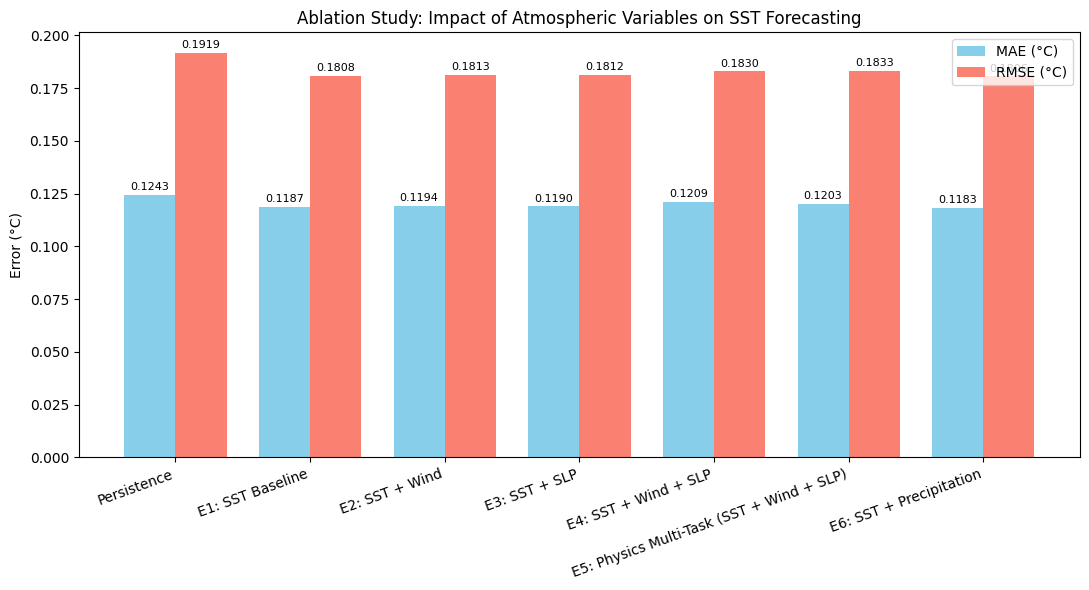

✅ Saved: reports/ablation_study_results.png


In [51]:

# ## 6. Ablation Study (E1–E6)
#
# ทุกการทดลองใช้ train/val/test ชุดเดียวกัน, seed เดียวกัน, epoch และ early stopping เท่ากัน
#
# | รหัส | Input | หมายเหตุ |
# |------|-------|----------|
# | E1 | SST | baseline ของ CNN |
# | E2 | SST + Wind | |
# | E3 | SST + SLP | |
# | E4 | SST + Wind + SLP | |
# | E5 | SST + Wind + SLP | Multi-task (ทำนาย SST + SLP) + Physics loss |
# | E6 | SST + Precipitation | |

# %%
EXPERIMENTS = [
    dict(name="E1: SST Baseline", inputs=("sst",)),
    dict(name="E2: SST + Wind", inputs=("sst", "wind")),
    dict(name="E3: SST + SLP", inputs=("sst", "slp")),
    dict(name="E4: SST + Wind + SLP", inputs=("sst", "wind", "slp")),
    dict(name="E5: Physics Multi-Task (SST + Wind + SLP)",
         inputs=("sst", "wind", "slp"), targets=("sst", "slp"),
         physics_weight=0.1, hidden=(32, 32, 16)),
    dict(name="E6: SST + Precipitation", inputs=("sst", "precip")),
]

trained_models = {}
rows = []
base_mae, base_rmse = score(actual_test, persistence_test, eval_mask)
rows.append({"Experiment": "Persistence", "MAE": base_mae, "RMSE": base_rmse})

for cfg in EXPERIMENTS:
    model, metrics = run_experiment(**cfg)
    trained_models[cfg["name"]] = model
    rows.append(metrics)


# ### 6.1 สรุปผล
results_df = pd.DataFrame(rows)
e1_mae = results_df.loc[results_df["Experiment"] == "E1: SST Baseline", "MAE"].item()
e1_rmse = results_df.loc[results_df["Experiment"] == "E1: SST Baseline", "RMSE"].item()
results_df["MAE gain vs E1 (%)"] = (e1_mae - results_df["MAE"]) / e1_mae * 100
results_df["RMSE gain vs E1 (%)"] = (e1_rmse - results_df["RMSE"]) / e1_rmse * 100

print(f"=== Ablation Study Results (Test: 2021, {len(test_targets)} days) ===")
display(results_df.round(4))
results_df.to_csv(REPORT_DIR / "ablation_results.csv", index=False)
print("✅ Saved: reports/ablation_results.csv")

# ### 6.2 กราฟเปรียบเทียบ
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.38

mae_bars = ax.bar(x - width / 2, results_df["MAE"], width, label="MAE (°C)", color="skyblue")
rmse_bars = ax.bar(x + width / 2, results_df["RMSE"], width, label="RMSE (°C)", color="salmon")
for bars in (mae_bars, rmse_bars):
    ax.bar_label(bars, fmt="%.4f", fontsize=8, padding=2)

ax.set_ylabel("Error (°C)")
ax.set_title("Ablation Study: Impact of Atmospheric Variables on SST Forecasting")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Experiment"], rotation=20, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "ablation_study_results.png", dpi=150)
plt.show()
print("✅ Saved: reports/ablation_study_results.png")


Forecast origins: 359 | 2021-01-01 to 2021-12-25
✅ Recursive forecasting completed.


,Forecast Horizon (days),Persistence MAE,CNN MAE,MAE Improvement (%),Persistence RMSE,CNN RMSE,RMSE Improvement (%)
0,1,0.1245,0.1188,4.5323,0.1923,0.1811,5.7874
1,3,0.2658,0.2529,4.8652,0.3720,0.3528,5.1650
2,7,0.3962,0.3709,6.3912,0.5503,0.5172,6.0105


✅ Saved: reports/forecast_horizon_results.csv


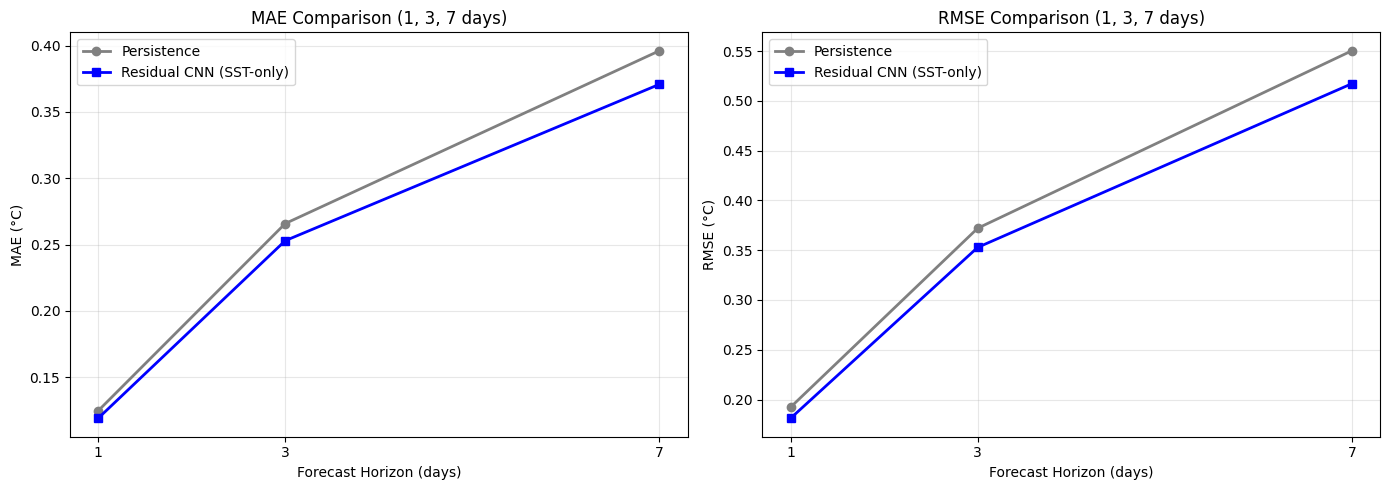

✅ Saved: reports/forecast_horizon_comparison.png


In [52]:

# ## 7. Multi-step Forecast (Recursive)
#
# ใช้โมเดล SST-only (E1) ทำนายวันถัดไป แล้วป้อนผลกลับเข้า input เพื่อทำนายต่อ
# จุดเริ่มต้นพยากรณ์ใช้ทุกวันของปี 2021 ที่ยังเหลือ SST จริงให้เทียบครบ `max(EVAL_HORIZONS)` วัน

# %%
@torch.no_grad()
def recursive_forecast(model, origins, max_horizon, batch_size=16):
    """คืน {horizon: array (N, H, W) หน่วย °C}; horizon h = ทำนายวัน origin + h - 1"""
    model.eval()
    outputs = {h: [] for h in range(1, max_horizon + 1)}

    for start in range(0, len(origins), batch_size):
        batch = origins[start:start + batch_size]
        history = np.stack([sst_norm[t - INPUT_DAYS:t] for t in batch]).astype(np.float32)  # (N, D, H, W)

        for h in range(1, max_horizon + 1):
            delta = model(torch.from_numpy(history).to(DEVICE))[:, 0].cpu().numpy()
            next_norm = history[:, -1] + delta
            next_norm[:, ~ocean_mask] = 0.0                       # ปิดพื้นที่ที่ไม่ใช่ทะเล
            outputs[h].append(next_norm * sst_std + sst_mean)     # แปลงกลับเป็น °C
            history = np.concatenate([history[:, 1:], next_norm[:, None]], axis=1)

    return {h: np.concatenate(v, axis=0).astype(np.float32) for h, v in outputs.items()}


max_horizon = max(EVAL_HORIZONS)
origins = np.arange(split_idx, T - max_horizon + 1)
print("Forecast origins:", len(origins), "|", dates_all[origins[0]].date(), "to", dates_all[origins[-1]].date())

forecasts = recursive_forecast(trained_models["E1: SST Baseline"], origins, max_horizon)
print("✅ Recursive forecasting completed.")


horizon_rows = []
for h in EVAL_HORIZONS:
    actual = sst_model[origins + h - 1]
    persistence = sst_model[origins - 1]
    mask = np.isfinite(actual) & np.isfinite(persistence) & ocean_mask[None]

    p_mae, p_rmse = score(actual, persistence, mask)
    m_mae, m_rmse = score(actual, forecasts[h], mask)
    horizon_rows.append({
        "Forecast Horizon (days)": h,
        "Persistence MAE": p_mae,
        "CNN MAE": m_mae,
        "MAE Improvement (%)": (p_mae - m_mae) / p_mae * 100,
        "Persistence RMSE": p_rmse,
        "CNN RMSE": m_rmse,
        "RMSE Improvement (%)": (p_rmse - m_rmse) / p_rmse * 100,
    })

horizon_df = pd.DataFrame(horizon_rows)
display(horizon_df.round(4))
horizon_df.to_csv(REPORT_DIR / "forecast_horizon_results.csv", index=False)
print("✅ Saved: reports/forecast_horizon_results.csv")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ("MAE", "RMSE")):
    ax.plot(horizon_df["Forecast Horizon (days)"], horizon_df[f"Persistence {metric}"],
            marker="o", label="Persistence", color="gray", linewidth=2)
    ax.plot(horizon_df["Forecast Horizon (days)"], horizon_df[f"CNN {metric}"],
            marker="s", label="Residual CNN (SST-only)", color="blue", linewidth=2)
    ax.set_xlabel("Forecast Horizon (days)")
    ax.set_ylabel(f"{metric} (°C)")
    ax.set_title(f"{metric} Comparison ({', '.join(map(str, EVAL_HORIZONS))} days)")
    ax.set_xticks(list(EVAL_HORIZONS))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(REPORT_DIR / "forecast_horizon_comparison.png", dpi=150)
plt.show()
print("✅ Saved: reports/forecast_horizon_comparison.png")